In [1]:
import os
import shutil
from google.colab import files

uploaded = files.upload()
if "kaggle.json" not in uploaded:
    raise FileNotFoundError("kaggle.json not found.")

os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
shutil.copy("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)

os.makedirs("/content/dataset/elliptic", exist_ok=True)
!kaggle datasets download -d ellipticco/elliptic-data-set -p /content/dataset/elliptic
!unzip -q /content/dataset/elliptic/elliptic-data-set.zip -d /content/dataset/elliptic
if os.path.exists("/content/dataset/elliptic/elliptic-data-set.zip"):
    os.remove("/content/dataset/elliptic/elliptic-data-set.zip")

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/ellipticco/elliptic-data-set
License(s): Attribution-NonCommercial-NoDerivatives 4.0 International (CC BY-NC-ND 4.0)
100% 146M/146M [00:08<00:00, 17.6MB/s]



In [4]:
!pip install -q torch-geometric

In [ ]:

import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from sklearn.preprocessing import StandardScaler
from typing import List, Tuple

class EllipticBitcoinDataset(Dataset):
    def __init__(self, dataset_dir: str, is_train: bool = True) -> None:
        super().__init__()
        self.dataset_dir = dataset_dir
        self.is_train = is_train
        self.graphs = self._prepare_data()

    def _prepare_data(self) -> List[Data]:
        df_features = pd.read_csv(os.path.join(self.dataset_dir, "elliptic_txs_features.csv"), header=None)
        df_features.rename(columns={0: 'txId', 1: 'time_step'}, inplace=True)

        df_classes = pd.read_csv(os.path.join(self.dataset_dir, "elliptic_txs_classes.csv"))
        df_edges = pd.read_csv(os.path.join(self.dataset_dir, "elliptic_txs_edgelist.csv"))

        df = df_features.merge(df_classes, on='txId', how='left')

        class_mapping = {'1': 1, '2': 0, 'unknown': -1}
        df['class'] = df['class'].map(class_mapping).fillna(-1).astype(int)

        feature_cols = [col for col in df.columns if col not in ['txId', 'time_step', 'class']]

        train_mask = df['time_step'] <= 34
        scaler = StandardScaler()
        df.loc[train_mask, feature_cols] = scaler.fit_transform(df.loc[train_mask, feature_cols])
        df.loc[~train_mask, feature_cols] = scaler.transform(df.loc[~train_mask, feature_cols])

        target_time_steps = range(1, 35) if self.is_train else range(35, 50)

        graphs_list = []
        for t in target_time_steps:
            df_t = df[df['time_step'] == t].reset_index(drop=True)
            if df_t.empty:
                continue

            x = torch.tensor(df_t[feature_cols].values, dtype=torch.float32)
            y = torch.tensor(df_t['class'].values, dtype=torch.long)
            labeled_mask = (y != -1)

            txid_to_idx = {txid: idx for idx, txid in enumerate(df_t['txId'])}
            current_txids = set(txid_to_idx.keys())

            mask_edges = df_edges['txId1'].isin(current_txids) & df_edges['txId2'].isin(current_txids)
            edges_t = df_edges[mask_edges]

            source_indices = [txid_to_idx[txid] for txid in edges_t['txId1']]
            target_indices = [txid_to_idx[txid] for txid in edges_t['txId2']]
            edge_index = torch.tensor([source_indices, target_indices], dtype=torch.long)

            graph_data = Data(
                x=x,
                edge_index=edge_index,
                y=y,
                labeled_mask=labeled_mask,
                time_step=torch.tensor([t], dtype=torch.long)
            )
            graphs_list.append(graph_data)

        return graphs_list

    def __len__(self) -> int:
        return len(self.graphs)

    def __getitem__(self, idx: int) -> Data:
        return self.graphs[idx]

def get_dataloaders(dataset_dir: str) -> Tuple[DataLoader, DataLoader]:
    train_dataset = EllipticBitcoinDataset(dataset_dir, is_train=True)
    test_dataset = EllipticBitcoinDataset(dataset_dir, is_train=False)

    train_loader = DataLoader(train_dataset, batch_size=1, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

    return train_loader, test_loader

if __name__ == "__main__":
    dataset_path = "/content/dataset/elliptic/elliptic_bitcoin_dataset"
    train_loader, test_loader = get_dataloaders(dataset_path)

    sample_batch = next(iter(train_loader))

    print(f"Time Step: {sample_batch.time_step.item()}")
    print(f"x shape: {sample_batch.x.shape} | dtype: {sample_batch.x.dtype}")
    print(f"edge_index shape: {sample_batch.edge_index.shape} | dtype: {sample_batch.edge_index.dtype}")
    print(f"y shape: {sample_batch.y.shape} | dtype: {sample_batch.y.dtype}")
    print(f"labeled_mask shape: {sample_batch.labeled_mask.shape} | dtype: {sample_batch.labeled_mask.dtype}")

    assert sample_batch.x.shape[1] in [165, 166], f"Invalid feature dimensions: {sample_batch.x.shape[1]}"
    assert sample_batch.edge_index.shape[0] == 2, "edge_index must have 2 rows."
    assert len(sample_batch.x) == len(sample_batch.y) == len(sample_batch.labeled_mask), "Node count mismatch."
    print("Sanity check passed successfully.")

Time Step: 3
x shape: torch.Size([6621, 165]) | dtype: torch.float32
edge_index shape: torch.Size([2, 8316]) | dtype: torch.int64
y shape: torch.Size([6621]) | dtype: torch.int64
labeled_mask shape: torch.Size([6621]) | dtype: torch.bool
Sanity check passed successfully.


In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

class GCN(nn.Module):
    """
    Standard 2-Layer Graph Convolutional Network.
    Architecture: (166 -> 100) -> ReLU -> Dropout -> (100 -> 2)
    """
    def __init__(self, in_features: int = 166, hidden_dim: int = 100, out_features: int = 2, dropout: float = 0.2):
        super(GCN, self).__init__()
        self.conv1 = GCNConv(in_features, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, out_features)
        self.dropout = nn.Dropout(dropout)

        # Initialize weights using Xavier Uniform (PyG does this by default, but we enforce it for consistency)
        nn.init.xavier_uniform_(self.conv1.lin.weight)
        nn.init.xavier_uniform_(self.conv2.lin.weight)

    def forward(self, x: torch.Tensor, edge_index: torch.Tensor) -> torch.Tensor:
        # Shape Input x: [N_t, 166], edge_index: [2, E_t]

        # Layer 1
        h1 = self.conv1(x, edge_index)           # Shape: [N_t, 100]
        h1 = F.relu(h1)                          # Shape: [N_t, 100]
        h1 = self.dropout(h1)                    # Shape: [N_t, 100]

        # Layer 2
        z_gcn = self.conv2(h1, edge_index)       # Shape: [N_t, 2]
        return z_gcn

class SkipLinearProjection(nn.Module):
    """
    Linear projection for the skip connection to match target output dimensions.
    Architecture: (166 -> 2)
    """
    def __init__(self, in_features: int = 166, out_features: int = 2):
        super(SkipLinearProjection, self).__init__()
        self.linear = nn.Linear(in_features, out_features, bias=False)
        nn.init.xavier_uniform_(self.linear.weight)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Shape Input x: [N_t, 166]
        z_skip = self.linear(x)                  # Shape: [N_t, 2]
        return z_skip

class SkipGCN(nn.Module):
    """
    Skip-GCN Architecture combining the 2-layer GCN path and the Linear Skip connection.
    Output undergoes LogSoftmax for binary classification (Licit vs Illicit).
    """
    def __init__(self, in_features: int = 166, hidden_dim: int = 100, out_features: int = 2, dropout: float = 0.2):
        super(SkipGCN, self).__init__()
        self.gcn_path = GCN(in_features, hidden_dim, out_features, dropout)
        self.skip_path = SkipLinearProjection(in_features, out_features)

    def forward(self, x: torch.Tensor, edge_index: torch.Tensor) -> torch.Tensor:
        # Shape Input x: [N_t, 166]

        # Compute both paths
        z_gcn = self.gcn_path(x, edge_index)     # Shape: [N_t, 2]
        z_skip = self.skip_path(x)               # Shape: [N_t, 2]

        # Element-wise Addition
        h_tilde = z_gcn + z_skip                 # Shape: [N_t, 2]

        # Output Activation (LogSoftmax preferred when using NLLLoss, equivalent to CrossEntropyLoss on raw logits)
        out = F.log_softmax(h_tilde, dim=-1)     # Shape: [N_t, 2]

        return out

# --- Dummy Tensor Shape Contract Test ---
if __name__ == "__main__":
    print("\n--- Dummy Forward Pass Shape Test ---")
    # Simulate a Graph for one time step with N_t = 1500 nodes and E_t = 3000 edges
    N_t = 1500
    E_t = 3000
    dummy_x = torch.randn((N_t, 166))

    # Create random edge connections
    source_nodes = torch.randint(0, N_t, (E_t,))
    target_nodes = torch.randint(0, N_t, (E_t,))
    dummy_edge_index = torch.stack([source_nodes, target_nodes], dim=0)

    # Initialize Model
    model = SkipGCN(in_features=166, hidden_dim=100, out_features=2, dropout=0.2)

    # Forward Pass
    output_logits = model(dummy_x, dummy_edge_index)

    print(f"Input Features Shape: {dummy_x.shape}")
    print(f"Input Edge Index Shape: {dummy_edge_index.shape}")
    print(f"Output Tensor Shape: {output_logits.shape}")

    # Verification checks
    assert output_logits.shape == (N_t, 2), f"Error: Expected output shape ({N_t}, 2), got {output_logits.shape}"
    print("Shape Contract Test Passed!")


--- Dummy Forward Pass Shape Test ---
Input Features Shape: torch.Size([1500, 166])
Input Edge Index Shape: torch.Size([2, 3000])
Output Tensor Shape: torch.Size([1500, 2])
Shape Contract Test Passed!


In [10]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
from tqdm.auto import tqdm

def train_and_evaluate(
    model: nn.Module,
    train_loader,
    test_loader,
    device: torch.device,
    epochs: int = 1000,
    lr: float = 0.001
) -> nn.Module:
    model = model.to(device)

    class_weights = torch.tensor([0.3, 0.7], dtype=torch.float32).to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.5, patience=50
    )

    best_test_f1_illicit = 0.0
    best_model_path = "/content/skip_gcn_best.pth"

    epoch_pbar = tqdm(range(1, epochs + 1), desc="Training Progress")

    for epoch in epoch_pbar:
        model.train()
        total_loss = 0.0
        optimizer.zero_grad()

        for batch in train_loader:
            batch = batch.to(device)
            logits = model(batch.x, batch.edge_index)

            mask = batch.labeled_mask
            if mask.sum() > 0:
                loss = criterion(logits[mask], batch.y[mask])
                loss.backward()
                total_loss += loss.item()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        avg_train_loss = total_loss / len(train_loader)

        if epoch % 50 == 0 or epoch == epochs:
            model.eval()
            all_preds = []
            all_targets = []

            with torch.no_grad():
                for batch in test_loader:
                    batch = batch.to(device)
                    logits = model(batch.x, batch.edge_index)

                    mask = batch.labeled_mask
                    if mask.sum() > 0:
                        preds = torch.argmax(logits[mask], dim=1)
                        targets = batch.y[mask]

                        all_preds.append(preds.cpu().numpy())
                        all_targets.append(targets.cpu().numpy())

            if all_preds:
                all_preds = np.concatenate(all_preds)
                all_targets = np.concatenate(all_targets)

                precision = precision_score(all_targets, all_preds, pos_label=1, zero_division=0)
                recall = recall_score(all_targets, all_preds, pos_label=1, zero_division=0)
                f1_illicit = f1_score(all_targets, all_preds, pos_label=1, zero_division=0)
                micro_f1 = f1_score(all_targets, all_preds, average='micro')

                scheduler.step(f1_illicit)

                if f1_illicit > best_test_f1_illicit:
                    best_test_f1_illicit = f1_illicit
                    torch.save(model.state_dict(), best_model_path)

                epoch_pbar.set_postfix({
                    "Loss": f"{avg_train_loss:.4f}",
                    "F1-Illicit": f"{f1_illicit:.4f}",
                    "Best-F1": f"{best_test_f1_illicit:.4f}",
                    "Micro-F1": f"{micro_f1:.4f}"
                })
        else:
            epoch_pbar.set_postfix({"Loss": f"{avg_train_loss:.4f}"})

    print(f"\nTraining completed. Best Test F1 (Illicit): {best_test_f1_illicit:.4f}")
    print(f"Best model weights saved to: {best_model_path}")

    return model

if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = SkipGCN(in_features=165, hidden_dim=100, out_features=2, dropout=0.2)

    trained_model = train_and_evaluate(
        model=model,
        train_loader=train_loader,
        test_loader=test_loader,
        device=device,
        epochs=1000,
        lr=0.001
    )

Training Progress:   0%|          | 0/1000 [00:00<?, ?it/s]


Training completed. Best Test F1 (Illicit): 0.5774
Best model weights saved to: /content/skip_gcn_best.pth


In [11]:
import torch
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

def evaluate_per_timestep(model: torch.nn.Module, test_loader, weights_path: str, device: torch.device):
    model.load_state_dict(torch.load(weights_path, map_location=device))
    model.to(device)
    model.eval()

    results = []

    with torch.no_grad():
        for batch in test_loader:
            batch = batch.to(device)
            t = batch.time_step.item()
            mask = batch.labeled_mask

            if mask.sum() == 0:
                continue

            logits = model(batch.x, batch.edge_index)
            preds = torch.argmax(logits[mask], dim=1).cpu().numpy()
            targets = batch.y[mask].cpu().numpy()

            n_illicit = int((targets == 1).sum())
            n_licit = int((targets == 0).sum())

            prec = precision_score(targets, preds, pos_label=1, zero_division=0)
            rec = recall_score(targets, preds, pos_label=1, zero_division=0)
            f1 = f1_score(targets, preds, pos_label=1, zero_division=0)

            results.append({
                "Time Step": t,
                "Licit Count": n_licit,
                "Illicit Count": n_illicit,
                "Precision": round(prec, 4),
                "Recall": round(rec, 4),
                "F1 (Illicit)": round(f1, 4)
            })

    df_results = pd.DataFrame(results)
    return df_results

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
eval_model = SkipGCN(in_features=165, hidden_dim=100, out_features=2, dropout=0.2)
df_eval = evaluate_per_timestep(eval_model, test_loader, "/content/skip_gcn_best.pth", device)
print(df_eval.to_string(index=False))

 Time Step  Licit Count  Illicit Count  Precision  Recall  F1 (Illicit)
        35         1159            182     0.8659  0.7802        0.8208
        36         1675             33     0.3065  0.5758        0.4000
        37          458             40     0.6667  0.5000        0.5714
        38          645            111     0.7500  0.7297        0.7397
        39         1102             81     0.6986  0.6296        0.6623
        40         1099            112     0.8136  0.4286        0.5614
        41         1016            116     0.7263  0.5948        0.6540
        42         1915            239     0.8098  0.5523        0.6567
        43         1346             24     0.0000  0.0000        0.0000
        44         1567             24     0.0556  0.0417        0.0476
        45         1216              5     0.0000  0.0000        0.0000
        46          710              2     0.0000  0.0000        0.0000
        47          824             22     0.0667  0.0455       

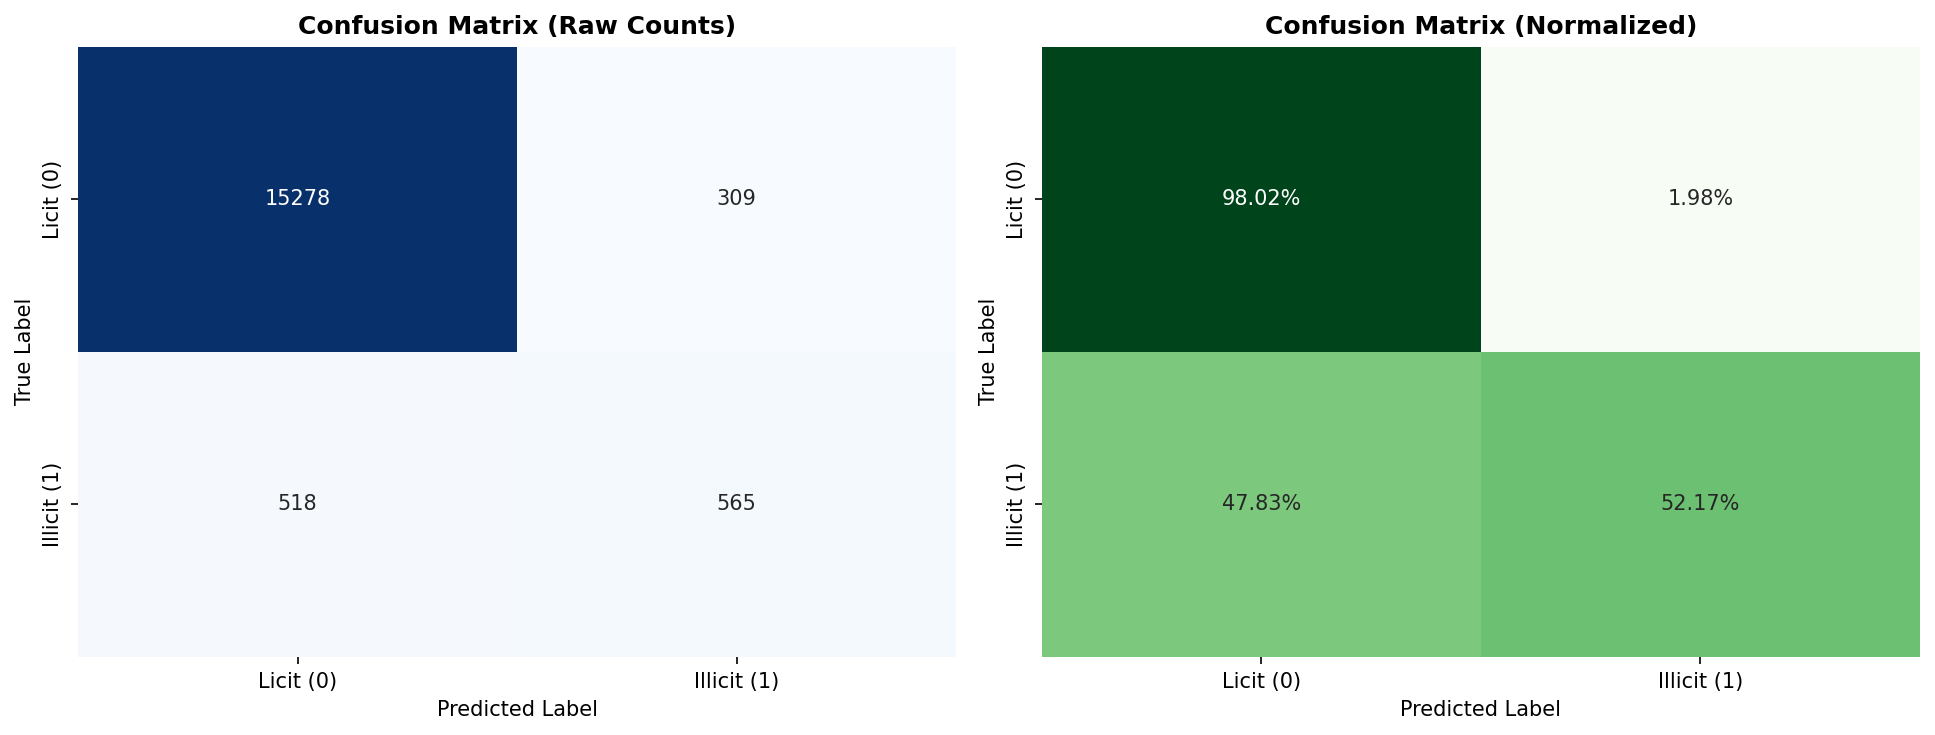

              precision  recall  f1-score     support
Licit            0.9672  0.9802    0.9736  15587.0000
Illicit          0.6465  0.5217    0.5774   1083.0000
accuracy         0.9504  0.9504    0.9504      0.9504
macro avg        0.8068  0.7509    0.7755  16670.0000
weighted avg     0.9464  0.9504    0.9479  16670.0000


In [12]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SkipGCN(in_features=165, hidden_dim=100, out_features=2, dropout=0.2).to(device)
model.load_state_dict(torch.load("/content/skip_gcn_best.pth", map_location=device))
model.eval()

all_preds = []
all_targets = []
all_probs = []

with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device)
        mask = batch.labeled_mask
        if mask.sum() > 0:
            logits = model(batch.x, batch.edge_index)
            probs = torch.softmax(logits[mask], dim=-1)[:, 1]
            preds = torch.argmax(logits[mask], dim=-1)

            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(batch.y[mask].cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

y_true = np.array(all_targets)
y_pred = np.array(all_preds)
y_prob = np.array(all_probs)

cm = confusion_matrix(y_true, y_pred)
cm_norm = confusion_matrix(y_true, y_pred, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=150)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Licit (0)', 'Illicit (1)'],
            yticklabels=['Licit (0)', 'Illicit (1)'])
axes[0].set_title('Confusion Matrix (Raw Counts)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', cbar=False, ax=axes[1],
            xticklabels=['Licit (0)', 'Illicit (1)'],
            yticklabels=['Licit (0)', 'Illicit (1)'])
axes[1].set_title('Confusion Matrix (Normalized)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

report_dict = classification_report(y_true, y_pred, target_names=['Licit', 'Illicit'], output_dict=True)
df_report = pd.DataFrame(report_dict).transpose()
print(df_report.round(4))

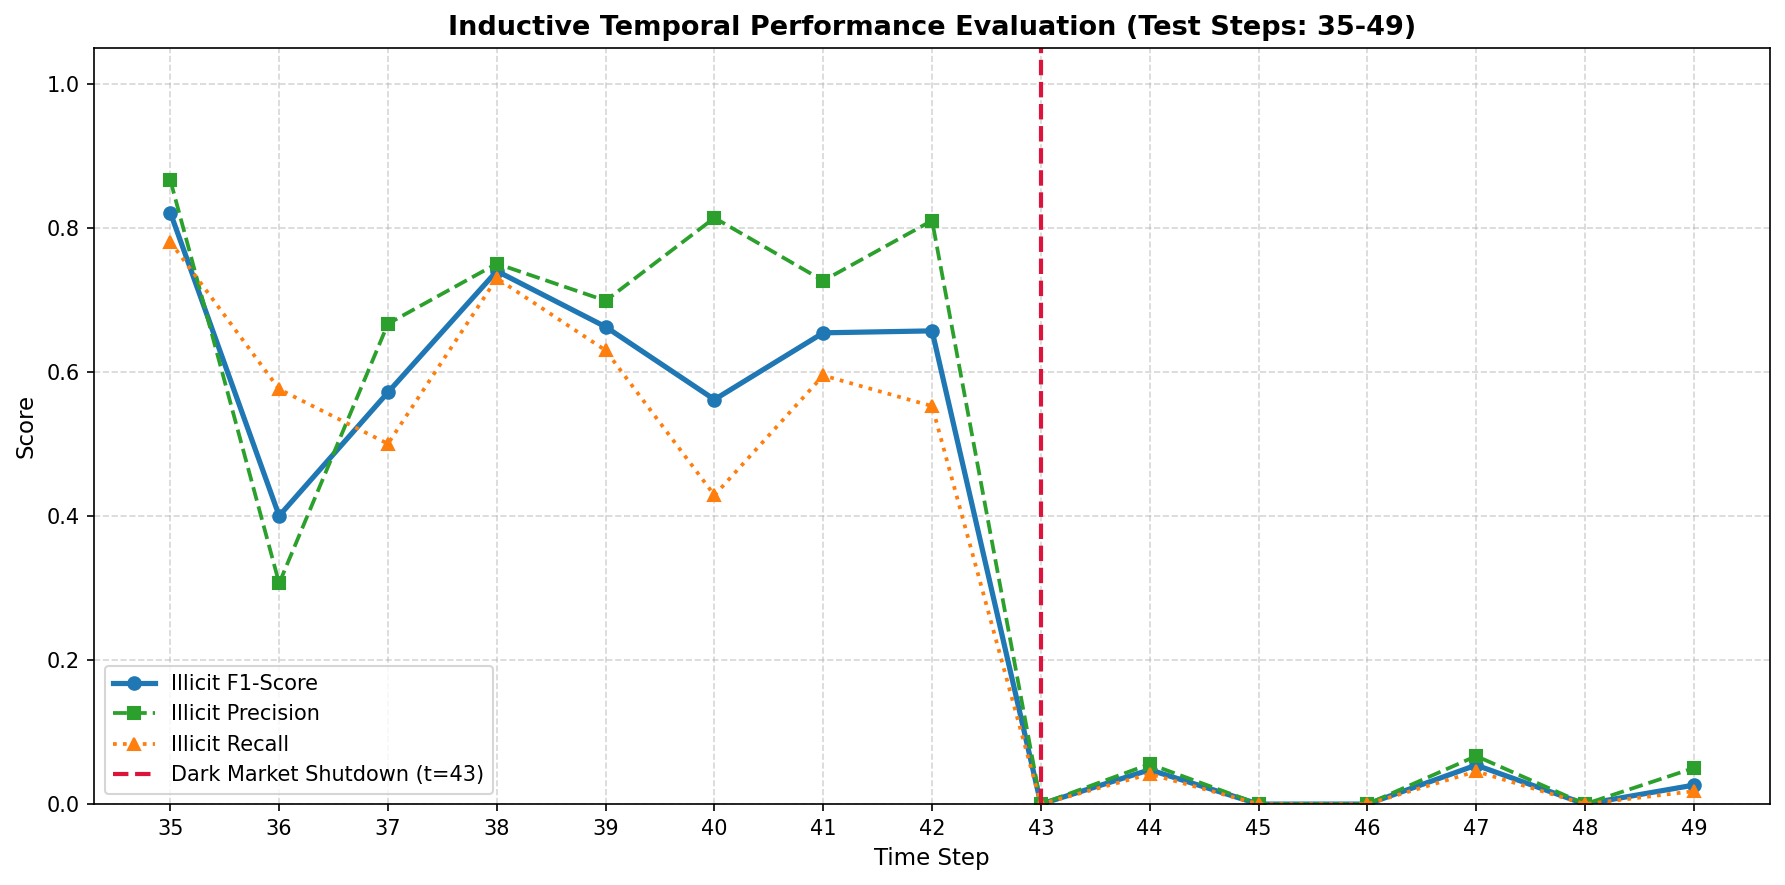

In [13]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

results = []

with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device)
        t = batch.time_step.item()
        mask = batch.labeled_mask

        if mask.sum() == 0:
            continue

        logits = model(batch.x, batch.edge_index)
        preds = torch.argmax(logits[mask], dim=-1).cpu().numpy()
        targets = batch.y[mask].cpu().numpy()

        n_illicit = int((targets == 1).sum())
        n_licit = int((targets == 0).sum())

        prec = precision_score(targets, preds, pos_label=1, zero_division=0)
        rec = recall_score(targets, preds, pos_label=1, zero_division=0)
        f1 = f1_score(targets, preds, pos_label=1, zero_division=0)

        results.append({
            'time_step': t,
            'licit': n_licit,
            'illicit': n_illicit,
            'precision': prec,
            'recall': rec,
            'f1_illicit': f1
        })

df_temporal = pd.DataFrame(results).sort_values('time_step')

plt.figure(figsize=(12, 6), dpi=150)
plt.plot(df_temporal['time_step'], df_temporal['f1_illicit'], marker='o', linewidth=2.5, color='#1f77b4', label='Illicit F1-Score')
plt.plot(df_temporal['time_step'], df_temporal['precision'], marker='s', linestyle='--', linewidth=1.8, color='#2ca02c', label='Illicit Precision')
plt.plot(df_temporal['time_step'], df_temporal['recall'], marker='^', linestyle=':', linewidth=1.8, color='#ff7f0e', label='Illicit Recall')

plt.axvline(x=43, color='crimson', linestyle='--', linewidth=2, label='Dark Market Shutdown (t=43)')
plt.title('Inductive Temporal Performance Evaluation (Test Steps: 35-49)', fontsize=13, fontweight='bold')
plt.xlabel('Time Step', fontsize=11)
plt.ylabel('Score', fontsize=11)
plt.xticks(df_temporal['time_step'])
plt.ylim(0.0, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.show()

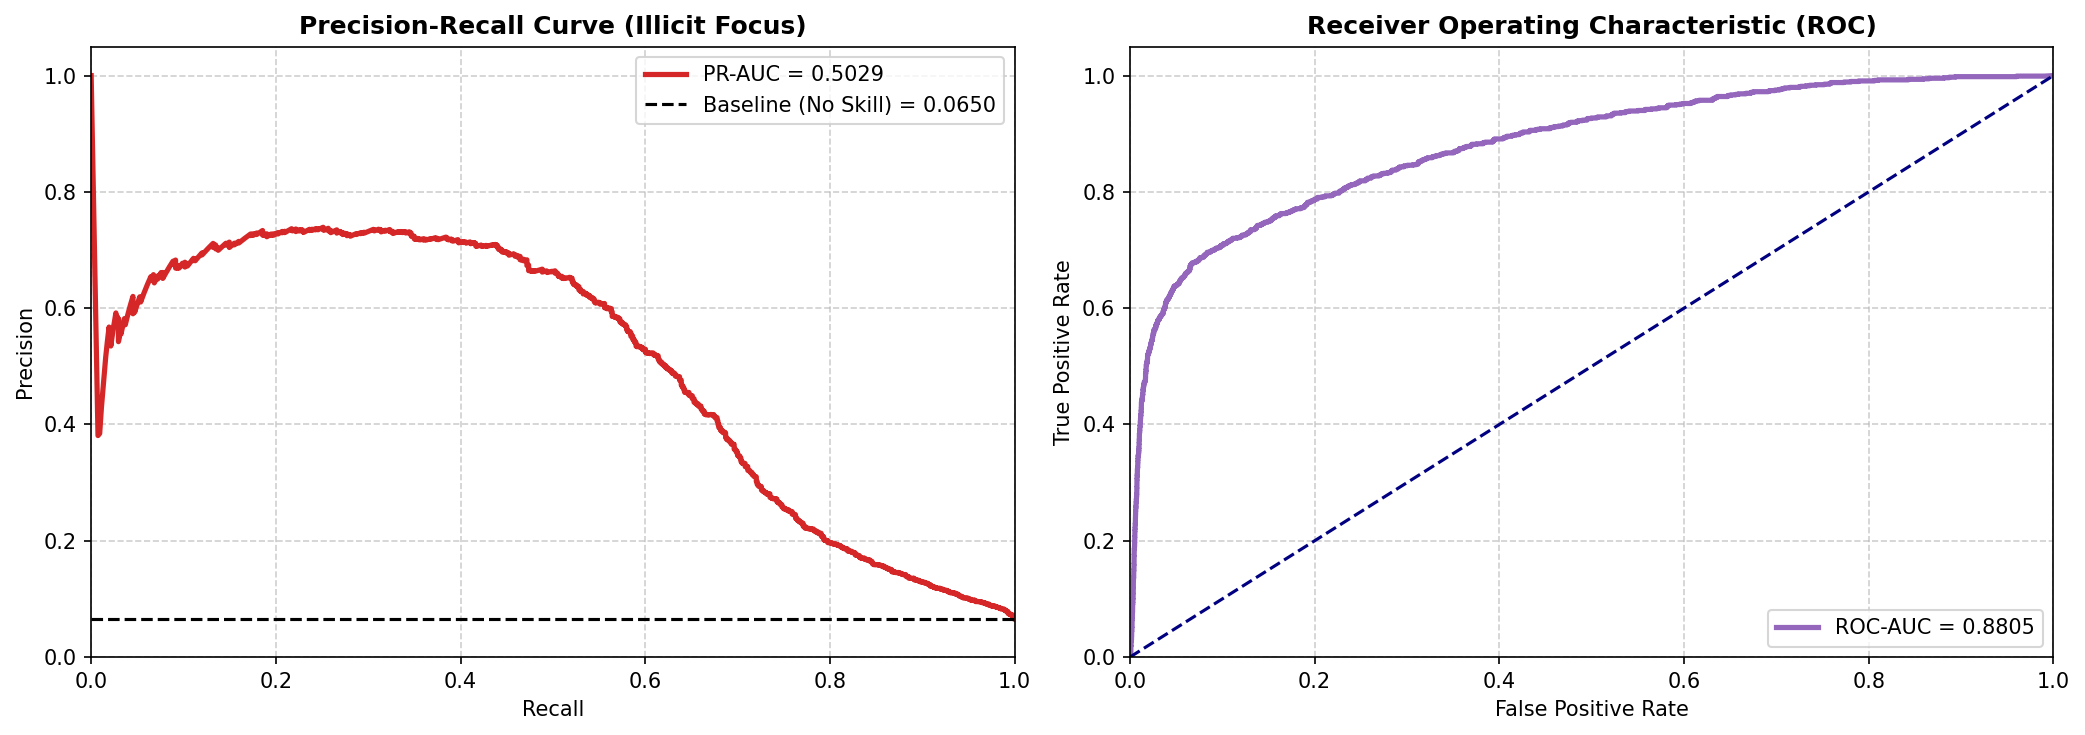

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

precision_vals, recall_vals, _ = precision_recall_curve(y_true, y_prob)
pr_auc = average_precision_score(y_true, y_prob)

baseline_ratio = np.sum(y_true == 1) / len(y_true)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

axes[0].plot(recall_vals, precision_vals, color='#d62728', lw=2.5, label=f'PR-AUC = {pr_auc:.4f}')
axes[0].axhline(y=baseline_ratio, color='black', linestyle='--', label=f'Baseline (No Skill) = {baseline_ratio:.4f}')
axes[0].set_title('Precision-Recall Curve (Illicit Focus)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(loc='upper right')

axes[1].plot(fpr, tpr, color='#9467bd', lw=2.5, label=f'ROC-AUC = {roc_auc:.4f}')
axes[1].plot([0, 1], [0, 1], color='navy', linestyle='--')
axes[1].set_title('Receiver Operating Characteristic (ROC)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

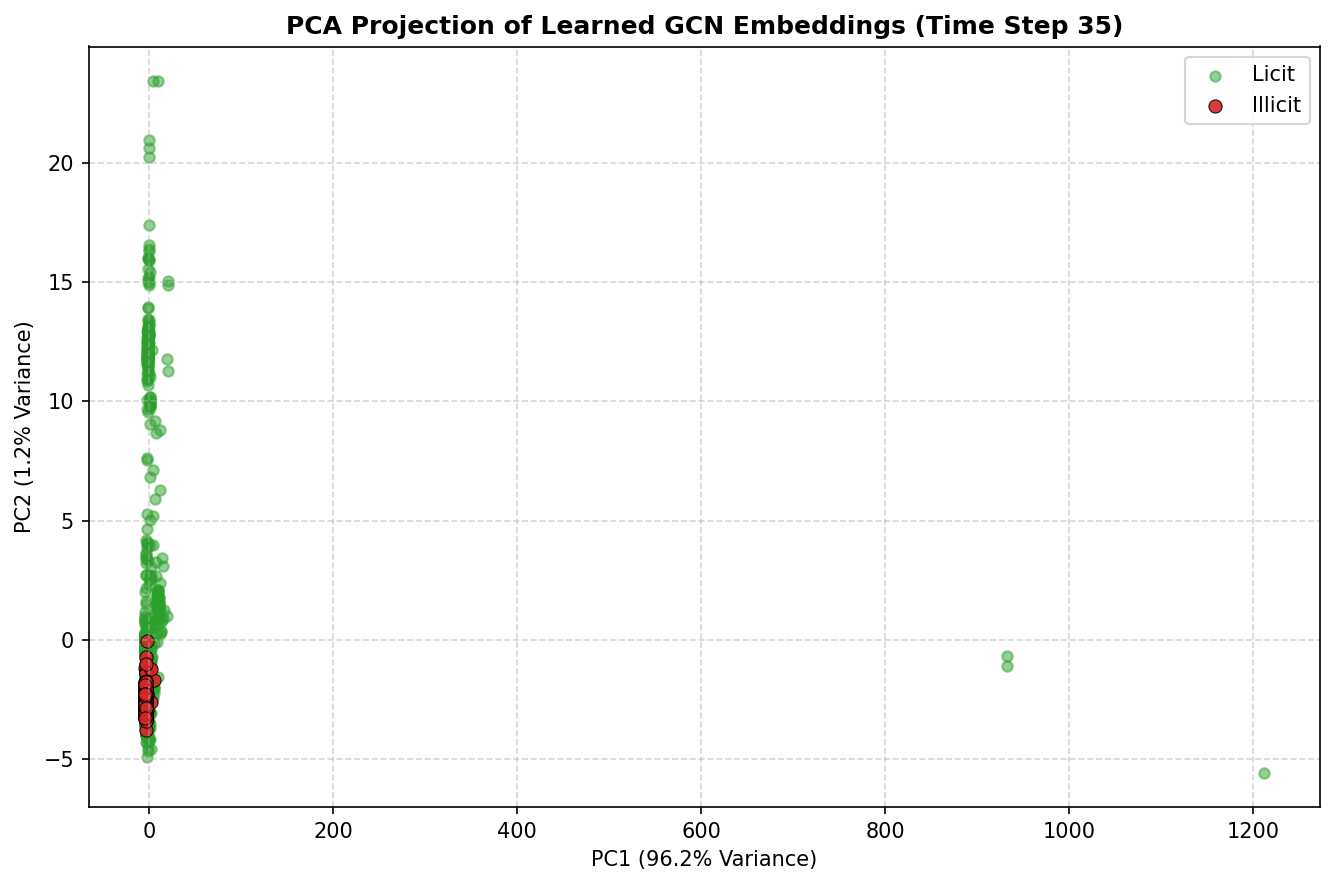

In [15]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

sample_eval_batch = None
with torch.no_grad():
    for batch in test_loader:
        if (batch.y[batch.labeled_mask] == 1).sum() > 20:
            sample_eval_batch = batch.to(device)
            break

if sample_eval_batch is not None:
    model.eval()
    with torch.no_grad():
        h1 = model.gcn_path.conv1(sample_eval_batch.x, sample_eval_batch.edge_index)
        embeddings = torch.relu(h1)

        mask = sample_eval_batch.labeled_mask
        features_sub = embeddings[mask].cpu().numpy()
        labels_sub = sample_eval_batch.y[mask].cpu().numpy()

    pca = PCA(n_components=2)
    proj = pca.fit_transform(features_sub)

    plt.figure(figsize=(9, 6), dpi=150)
    plt.scatter(proj[labels_sub == 0, 0], proj[labels_sub == 0, 1],
                c='#2ca02c', alpha=0.5, s=25, label='Licit')
    plt.scatter(proj[labels_sub == 1, 0], proj[labels_sub == 1, 1],
                c='#d62728', alpha=0.9, s=40, edgecolors='black', linewidth=0.5, label='Illicit')

    plt.title(f'PCA Projection of Learned GCN Embeddings (Time Step {sample_eval_batch.time_step.item()})', fontsize=12, fontweight='bold')
    plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)')
    plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(frameon=True)
    plt.tight_layout()
    plt.show()